In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [2]:
df = pd.read_csv("cleaned_full.csv")
y = df["diagnosis"].values                     # 1 = malignant, 0 = benign
X = df.drop(columns=["id", "diagnosis"])
Xs = StandardScaler().fit_transform(X)

print(Xs.shape)                                # expect (569, 30)
print(np.bincount(y))                          # expect [357 212]
print(Xs.mean(axis=0).round(2)[:5], Xs.std(axis=0).round(2)[:5])  # ~0 and ~1

(569, 30)
[357 212]
[-0.  0. -0. -0. -0.] [1. 1. 1. 1. 1.]


In [3]:
pca = PCA(random_state=42).fit(Xs)
cum_var = np.cumsum(pca.explained_variance_ratio_)
n_pc = int(np.argmax(cum_var >= 0.90)) + 1
print(n_pc, "PCs explain", round(cum_var[n_pc - 1], 3))

Xp = pca.transform(Xs)[:, :n_pc]
print(Xp.shape)    # expect (569, n_pc)

7 PCs explain 0.91
(569, 7)


In [4]:
datasets = {"full": Xs, "PCA": Xp}
linkages = ["single", "complete", "average"]

trees, labels = {}, {}
for dname, data in datasets.items():
    for link in linkages:
        Z = linkage(data, method=link)
        trees[(link, dname)] = Z
        labels[(link, dname)] = fcluster(Z, t=2, criterion="maxclust")

for key, lab in labels.items():
    print(key, np.bincount(lab)[1:])

('single', 'full') [  2 567]
('complete', 'full') [  2 567]
('average', 'full') [  3 566]
('single', 'PCA') [  2 567]
('complete', 'PCA') [  2 567]
('average', 'PCA') [  2 567]


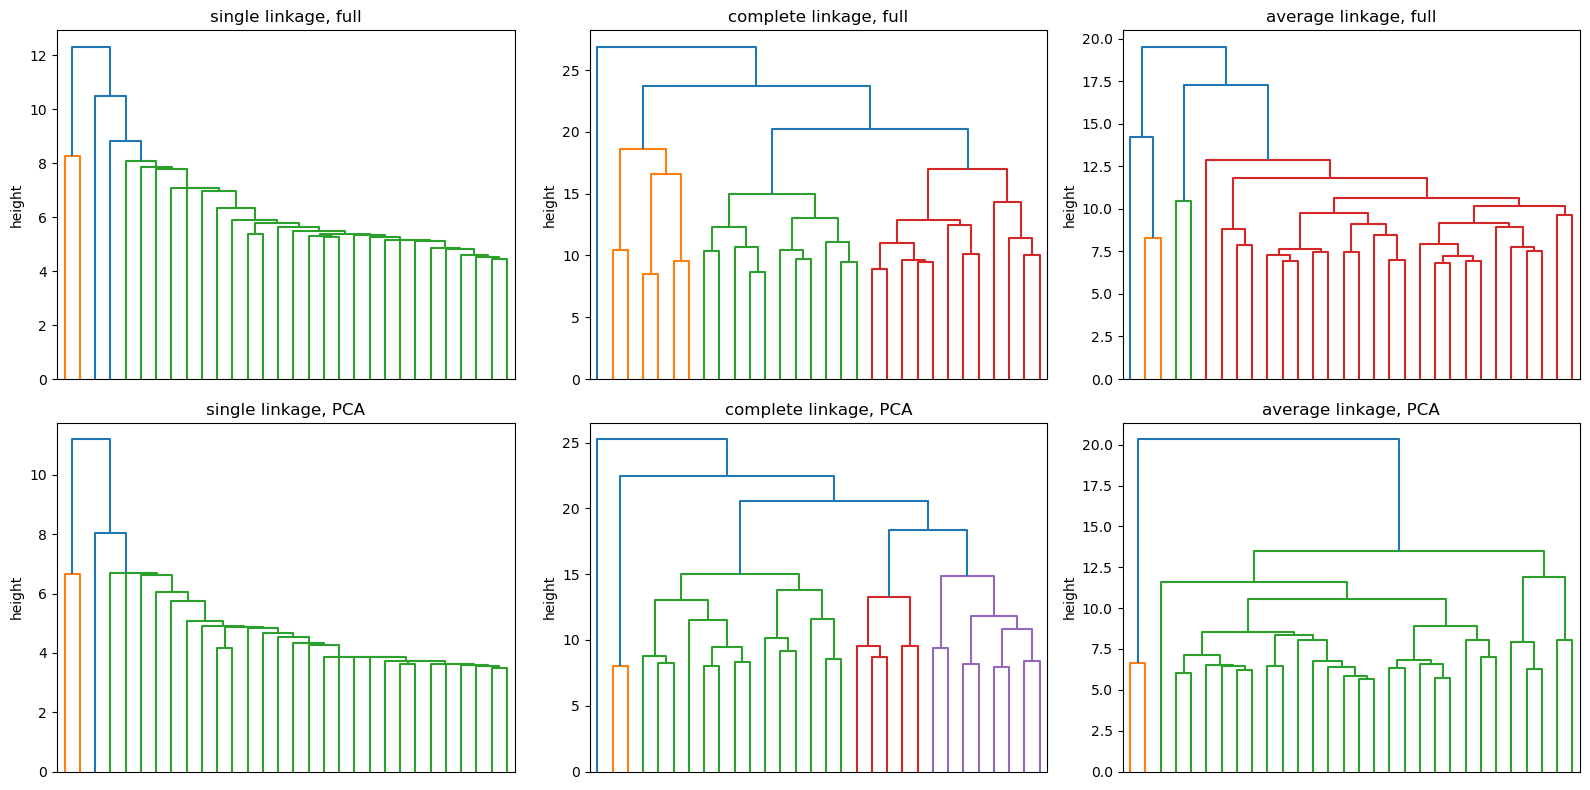

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax_row, dname in zip(axes, datasets):
    for ax, link in zip(ax_row, linkages):
        dendrogram(trees[(link, dname)], truncate_mode="lastp", p=30,
                   no_labels=True, ax=ax)
        ax.set_title(f"{link} linkage, {dname}")
        ax.set_ylabel("height")
plt.tight_layout()
plt.savefig("dendrograms.png", dpi=150)
plt.show()

In [6]:
from sklearn.metrics import calinski_harabasz_score

ks = range(2, 11)
ch = {}
for (link, dname), Z in trees.items():
    data = datasets[dname]
    scores = []
    for k in ks:
        lab = fcluster(Z, t=k, criterion="maxclust")
        scores.append(calinski_harabasz_score(data, lab))
    ch[(link, dname)] = scores

ch_table = pd.DataFrame(ch, index=list(ks)).round(1)
ch_table.index.name = "K"
ch_table

,single,complete,average,single,complete,average
,full,full,full,PCA,PCA,PCA
K,,,,,,
2,27.9,27.9,32.5,29.3,29.3,29.3
3,21.1,32.5,25.9,21.3,23.6,30.3
4,15.8,111.9,18.9,15.7,96.6,22.6
5,12.2,88.7,15.5,13.8,87.9,18.2
6,11.7,85.1,17.4,11.2,87.3,45.3
7,11.1,73.7,36.9,11.1,78.0,40.1
8,10.5,78.5,32.0,10.8,73.1,43.0
9,10.3,70.2,29.0,10.2,66.7,39.3


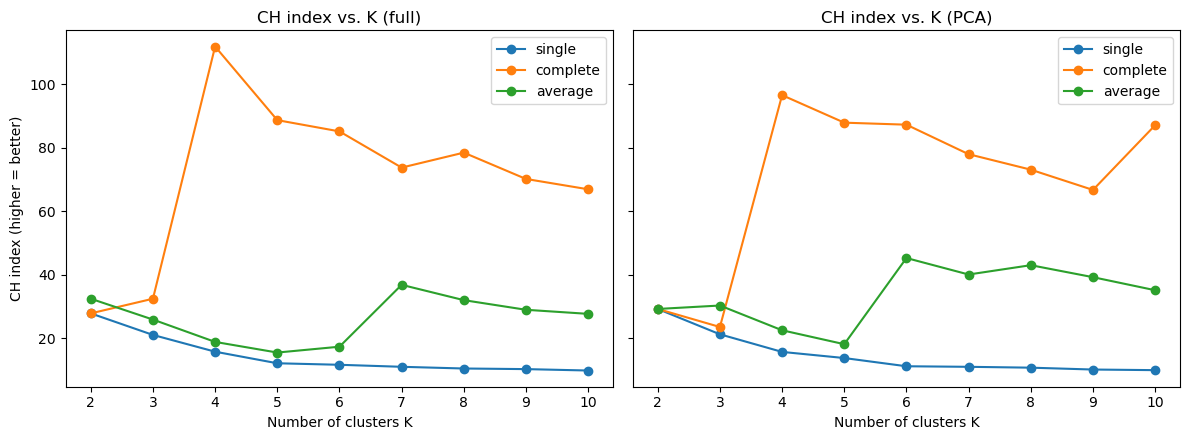

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, dname in zip(axes, ["full", "PCA"]):
    for link in linkages:
        ax.plot(list(ks), ch[(link, dname)], marker="o", label=link)
    ax.set_title(f"CH index vs. K ({dname})")
    ax.set_xlabel("Number of clusters K")
    ax.legend()

axes[0].set_ylabel("CH index (higher = better)")
plt.tight_layout()
plt.savefig("ch_index.png", dpi=150)
plt.show()

In [8]:
for key, lab in labels.items():
    ct = pd.crosstab(lab, y, rownames=["cluster"], colnames=["diagnosis"])
    print(key)
    print(ct)
    print()

('single', 'full')
diagnosis    0    1
cluster            
1            0    2
2          357  210

('complete', 'full')
diagnosis    0    1
cluster            
1            0    2
2          357  210

('average', 'full')
diagnosis    0    1
cluster            
1            0    3
2          357  209

('single', 'PCA')
diagnosis    0    1
cluster            
1            0    2
2          357  210

('complete', 'PCA')
diagnosis    0    1
cluster            
1            0    2
2          357  210

('average', 'PCA')
diagnosis    0    1
cluster            
1            0    2
2          357  210



In [9]:
for key, Z in trees.items():
    lab = fcluster(Z, t=4, criterion="maxclust")
    ct = pd.crosstab(lab, y, rownames=["cluster"], colnames=["diagnosis"])
    print(key, "- 4 clusters")
    print(ct)
    print()

('single', 'full') - 4 clusters
diagnosis    0    1
cluster            
1            0    2
2          356  209
3            0    1
4            1    0

('complete', 'full') - 4 clusters
diagnosis    0    1
cluster            
1            0    2
2            2    5
3           12  165
4          343   40

('average', 'full') - 4 clusters
diagnosis    0    1
cluster            
1            0    2
2            0    1
3            2    0
4          355  209

('single', 'PCA') - 4 clusters
diagnosis    0    1
cluster            
1            0    2
2          356  209
3            0    1
4            1    0

('complete', 'PCA') - 4 clusters
diagnosis    0    1
cluster            
1            0    2
2            2    0
3          350   97
4            5  113

('average', 'PCA') - 4 clusters
diagnosis    0    1
cluster            
1            0    2
2          355  206
3            0    4
4            2    0



In [10]:
rows = []
for key, Z in trees.items():
    for k in [2, 4]:
        lab = fcluster(Z, t=k, criterion="maxclust")
        ct = pd.crosstab(lab, y)
        acc = ct.max(axis=1).sum() / ct.values.sum()
        sizes = sorted(ct.sum(axis=1).tolist(), reverse=True)
        rows.append({"linkage": key[0], "data": key[1], "k": k,
                     "cluster sizes": sizes,
                     "accuracy": round(acc, 3)})

summary = pd.DataFrame(rows)
summary

,linkage,data,k,cluster sizes,accuracy
0,single,full,2,"[567, 2]",0.631
1,single,full,4,"[565, 2, 1, 1]",0.633
2,complete,full,2,"[567, 2]",0.631
3,complete,full,4,"[383, 177, 7, 2]",0.905
4,average,full,2,"[566, 3]",0.633
5,average,full,4,"[564, 2, 2, 1]",0.633
6,single,PCA,2,"[567, 2]",0.631
7,single,PCA,4,"[565, 2, 1, 1]",0.633
8,complete,PCA,2,"[567, 2]",0.631
9,complete,PCA,4,"[447, 118, 2, 2]",0.821


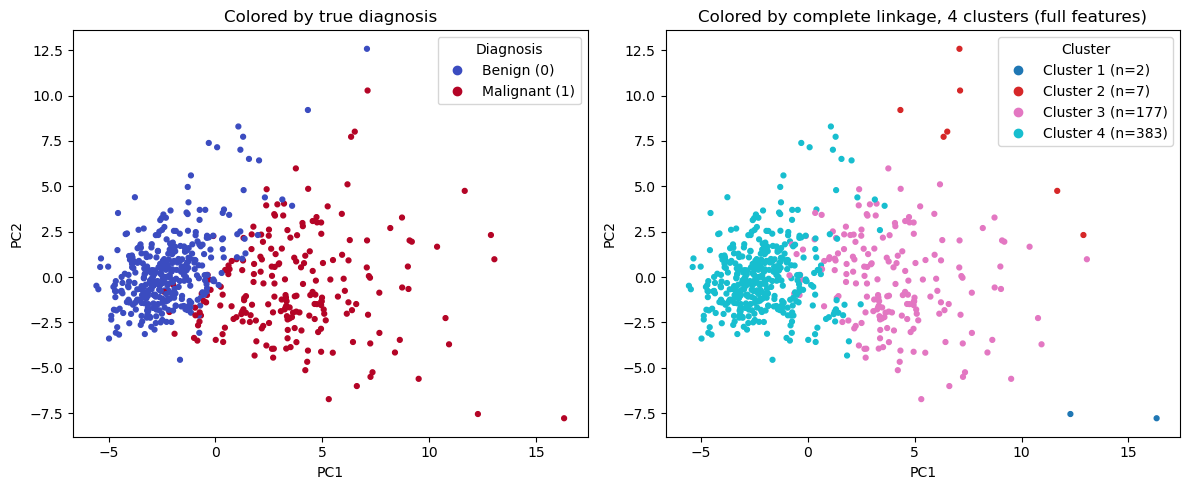

In [23]:
lab4 = fcluster(trees[("complete", "full")], t=4, criterion="maxclust")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sc1 = axes[0].scatter(Xp[:, 0], Xp[:, 1], c=y, cmap="coolwarm", s=12)
axes[0].set_title("Colored by true diagnosis")
handles1, _ = sc1.legend_elements()
axes[0].legend(handles1, ["Benign (0)", "Malignant (1)"], title="Diagnosis")

sc2 = axes[1].scatter(Xp[:, 0], Xp[:, 1], c=lab4, cmap="tab10", s=12)
axes[1].set_title("Colored by complete linkage, 4 clusters (full features)")
clusters, counts = np.unique(lab4, return_counts=True)
handles2, _ = sc2.legend_elements()
axes[1].legend(handles2,
               [f"Cluster {c} (n={n})" for c, n in zip(clusters, counts)],
               title="Cluster")

for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()
plt.savefig("clusters_vs_diagnosis.png", dpi=150)
plt.show()